In [1]:
%pip install matplotlib scipy

In [2]:
import math
import random
from collections import deque

INF = float("inf")

TASK = 1
BREAKDOWN = 2
PARTS_REQUEST = 3

PARAMS = {
    "arrival_mean": 1.0,
    "setup": (0.35, 0.15),
    "work": (0.5, 0.1),
    "uptime": (20.0, 2.0),
    "phase_mean": 0.75,
    "phases": 3,
    "keep": 3,
    "parts_mean": 100.0,
    "parts_delay": 3.0,
    "use_subcontractor": True,
    "use_spare_parts": True,
}


def validate_params(p):
    assert p["arrival_mean"] > 0 and p["phase_mean"] > 0 and p["parts_mean"] > 0
    assert p["setup"][0] - p["setup"][1] >= 0, "час наладки не може бути від'ємним"
    assert p["work"][0] > 0 and p["uptime"][0] > 0
    assert p["phases"] >= 1, "ремонт має складатися хоча б з однієї фази"
    assert p["keep"] >= 0 and p["parts_delay"] >= 0


class Generator:

    def __init__(self, seed):
        self.rnd = random.Random(seed)

    def r(self):
        return 1.0 - self.rnd.random()

    def exp(self, d):
        return -d * math.log(self.r())

    def unif(self, d, s):
        return d - s + 2 * s * self.rnd.random()

    def norm(self, d, s):
        while True:
            x = d + s * math.sqrt(-2 * math.log(self.r())) * math.cos(2 * math.pi * self.rnd.random())
            if x > 0:
                return x


class Request:

    def __init__(self, num, kind, t_in, phase=0):
        self.num = num
        self.kind = kind
        self.phase = phase
        self.t_in = t_in
        self.tau = None

    def label(self):
        return f"2.{self.phase}" if self.kind == BREAKDOWN else f"1#{self.num}"


class Source:

    def __init__(self, gen, mean):
        self.gen, self.mean = gen, mean
        self.t_next = gen.exp(mean)

    def schedule(self, now):
        self.t_next = now + self.gen.exp(self.mean)


class Device:

    def __init__(self, name):
        self.name = name
        self.request = None
        self.t_end = INF

    @property
    def busy(self):
        return self.request is not None

    def start(self, request, now, duration):
        self.request, self.t_end = request, now + duration

    def release(self):
        request, self.request, self.t_end = self.request, None, INF
        return request


class MachineModel:
    def __init__(self, seed=1, warmup=0.0, modified=False, params=PARAMS):
        self.p = {**PARAMS, **params}
        validate_params(self.p)
        self.gen = Generator(seed)
        self.modified = modified
        self.warmup = warmup
        self.trace = False
        self.now = 0.0

        self.src1 = Source(self.gen, self.p["arrival_mean"])
        self.queue1 = deque()
        self.d1 = Device("D1")
        self.d2 = Device("D2")
        self.d2.start(Request(0, BREAKDOWN, 0.0), 0.0, self.gen.norm(*self.p["uptime"]))
        self.src3 = Source(self.gen, self.p["parts_mean"]) if modified else None
        self.use_subcontractor = modified and self.p["use_subcontractor"]
        self.use_spare_parts = modified and self.p["use_spare_parts"]
        if modified and not self.use_spare_parts:
            self.src3.t_next = INF
        self.d3 = Device("D3")
        self.num = 0

        self.T = 0.0
        self.busy_job = 0.0
        self.busy_repair = 0.0
        self.queue_area = 0.0
        self.n_in = self.n_out = self.n_sub = 0
        self.n_fail = self.n_pause = self.n_refused = 0
        self.sum_w = self.sum_w2 = 0.0
        self.min_w, self.max_w = INF, 0.0
        self.keep_sojourns = False
        self.sojourns = []
        self.protocol = []

    def events(self):
        ev = [(self.d1.t_end, self.d1_done), (self.d2.t_end, self.d2_done)]
        if self.modified:
            ev.append((self.d3.t_end, self.d3_done))
        ev.append((self.src1.t_next, self.arrival1))
        if self.modified:
            ev.append((self.src3.t_next, self.arrival3))
        return ev

    def run(self, t_mod):
        while True:
            ev = self.events()
            t_next = min(t for t, _ in ev)
            if t_next > t_mod:
                self.collect(t_mod)
                self.now = t_mod
                return self
            self.collect(t_next)
            self.now = t_next
            for t, handler in ev:
                if t == t_next:
                    handler()
                    break

    def collect(self, t_next):
        dt = t_next - max(self.now, self.warmup)
        if dt <= 0:
            return
        self.T += dt
        if self.d1.busy:
            if self.d1.request.kind == TASK:
                self.busy_job += dt
            else:
                self.busy_repair += dt
        self.queue_area += len(self.queue1) * dt

    def counting(self):
        return self.now >= self.warmup

    def service_time(self, req):
        if req.kind == TASK:
            return self.gen.unif(*self.p["setup"]) + self.gen.norm(*self.p["work"])
        return self.gen.exp(self.p["phase_mean"])

    def try_start_d1(self):
        if not self.d1.busy and self.queue1:
            req = self.queue1.popleft()
            duration = req.tau if req.tau is not None else self.service_time(req)
            self.d1.start(req, self.now, duration)

    def arrival1(self):
        self.src1.schedule(self.now)
        self.num += 1
        self.n_in += self.counting()
        self.queue1.append(Request(self.num, TASK, self.now))
        self.try_start_d1()
        self.log("arrival of task")

    def d1_done(self):
        req = self.d1.release()
        if req.kind == TASK:
            if req.t_in >= self.warmup:
                w = self.now - req.t_in
                self.n_out += 1
                self.sum_w += w
                self.sum_w2 += w * w
                self.min_w = min(self.min_w, w)
                self.max_w = max(self.max_w, w)
                if self.keep_sojourns:
                    self.sojourns.append(w)
            event = f"task #{req.num} done"
        elif req.phase < self.p["phases"]:
            req.phase += 1
            self.d1.start(req, self.now, self.service_time(req))
            self.log(f"repair phase {req.phase}")
            return
        else:
            req.phase = 0
            self.d2.start(req, self.now, self.gen.norm(*self.p["uptime"]))
            event = "repair finished"
        self.try_start_d1()
        self.log(event)

    def d2_done(self):
        req = self.d2.release()
        req.phase = 1
        self.n_fail += 1
        interrupted = None
        if self.d1.busy:
            tau = self.d1.t_end - self.now
            interrupted = self.d1.release()
            interrupted.tau = tau
        if self.use_subcontractor and len(self.queue1) > self.p["keep"]:
            n_out = len(self.queue1) - self.p["keep"]
            for _ in range(n_out):
                self.queue1.popleft()
            if interrupted is not None:
                n_out += 1
                interrupted = None
            if self.counting():
                self.n_sub += n_out
        if interrupted is not None:
            self.queue1.appendleft(interrupted)
        self.d1.start(req, self.now, self.service_time(req))
        self.log("breakdown")

    def arrival3(self):
        self.src3.schedule(self.now)
        repairing = self.d1.busy and self.d1.request.kind == BREAKDOWN
        if not repairing or self.d3.busy:
            self.n_refused += 1
            return
        self.n_pause += 1
        self.d3.start(Request(0, PARTS_REQUEST, self.now), self.now, self.p["parts_delay"])
        self.d1.t_end += self.p["parts_delay"]
        self.log("repair paused")

    def d3_done(self):
        self.d3.release()
        self.log("parts delivered")

    def log(self, event):
        if self.trace:
            on_d1 = self.d1.request.label() if self.d1.busy else "-"
            head = self.queue1[0].label() if self.queue1 else "-"
            d3 = ("busy" if self.d3.busy else "free") if self.modified else ""
            self.protocol.append((self.now, event, len(self.queue1), head, on_d1,
                                  self.d1.t_end, self.d2.t_end, d3))
            print(f"{self.now:9.3f} | {event:18s} | L1 = {len(self.queue1):2d} | head: {head:6s} | "
                  f"D1: {on_d1:6s} | t1 = {self.d1.t_end:9.3f} | t2 = {self.d2.t_end:9.3f}"
                  + (f" | D3: {d3}" if self.modified else ""))

    def report(self):
        n = self.n_out
        mean_w = self.sum_w / n if n else 0.0
        var_w = (self.sum_w2 / n - mean_w ** 2) * n / (n - 1) if n > 1 else 0.0
        T = self.T if self.T > 0 else 1.0
        return {
            "U": self.busy_job / T,
            "P_rep": self.busy_repair / T,
            "W": mean_w,
            "sigma_W": math.sqrt(max(var_w, 0.0)),
            "W_min": self.min_w if n else 0.0,
            "W_max": self.max_w,
            "L": self.queue_area / T,
            "lambda_out": n / T,
            "P_sub": self.n_sub / self.n_in if self.n_in else 0.0,
        }


def replicate(n, t_mod, warmup, modified=False, params=PARAMS, seed0=1):
    try:
        from scipy.stats import t as student
        q = student.ppf(0.975, n - 1)
    except ImportError:
        q = 1.96
    runs = [MachineModel(seed0 + i, warmup, modified, params).run(t_mod).report() for i in range(n)]
    out = {}
    for key in runs[0]:
        v = [r[key] for r in runs]
        m = sum(v) / n
        s = math.sqrt(sum((x - m) ** 2 for x in v) / (n - 1))
        out[key] = (m, q * s / math.sqrt(n))
    return out

In [3]:
model = MachineModel(seed=1)
model.run(38.6)
model.trace = True
model.run(42.6)

   39.030 | task #45 done      | L1 =  2 | head: 1#47   | D1: 1#46   | t1 =    39.803 | t2 =    39.707
   39.707 | breakdown          | L1 =  3 | head: 1#46   | D1: 2.1    | t1 =    40.133 | t2 =       inf
   40.133 | repair phase 2     | L1 =  3 | head: 1#46   | D1: 2.2    | t1 =    40.294 | t2 =       inf
   40.294 | repair phase 3     | L1 =  3 | head: 1#46   | D1: 2.3    | t1 =    40.377 | t2 =       inf
   40.377 | repair finished    | L1 =  2 | head: 1#47   | D1: 1#46   | t1 =    40.473 | t2 =    59.532
   40.473 | task #46 done      | L1 =  1 | head: 1#48   | D1: 1#47   | t1 =    41.384 | t2 =    59.532
   41.384 | task #47 done      | L1 =  0 | head: -      | D1: 1#48   | t1 =    42.360 | t2 =    59.532
   41.708 | arrival of task    | L1 =  1 | head: 1#49   | D1: 1#48   | t1 =    42.360 | t2 =    59.532
   42.105 | arrival of task    | L1 =  2 | head: 1#49   | D1: 1#48   | t1 =    42.360 | t2 =    59.532
   42.360 | task #48 done      | L1 =  1 | head: 1#50   | D1: 1#49   | t1

In [5]:
for modified in (False, True):
    print("Модифікована модель" if modified else "Базова модель")
    for key, (mean, half) in replicate(10, 100_000, 1000, modified).items():
        print(f"  {key:10s} {mean:9.4f} ± {half:.4f}")

Базова модель
  U             0.8498 ± 0.0017
  P_rep         0.1014 ± 0.0005
  W            10.3139 ± 0.6778
  sigma_W       9.2526 ± 0.7904
  W_min         0.4099 ± 0.0162
  W_max        63.4675 ± 9.1500
  L             9.4634 ± 0.6938
  lambda_out    0.9996 ± 0.0019
  P_sub         0.0000 ± 0.0000
Модифікована модель
  U             0.8036 ± 0.0013
  P_rep         0.1035 ± 0.0006
  W             3.8237 ± 0.0211
  sigma_W       2.3502 ± 0.0183
  W_min         0.3799 ± 0.0257
  W_max        17.7716 ± 0.9213
  L             3.0788 ± 0.0270
  lambda_out    0.9385 ± 0.0015
  P_sub         0.0619 ± 0.0010


In [6]:
%matplotlib inline
import csv
import math
import os
import statistics as st

import matplotlib.pyplot as plt


OUT_DIR = os.environ.get("B19_OUT", "results")
SHOW_TABLES = True
SAMPLE_SIZE = 100_000
CHECK_RUNS = 5
CHECK_T_MOD = 100_000
CHECK_T_WARM = 1000


def save_table(filename, header, rows):
    os.makedirs(OUT_DIR, exist_ok=True)
    path = os.path.join(OUT_DIR, filename)
    with open(path, "w", newline="", encoding="utf-8-sig") as f:
        writer = csv.writer(f, delimiter=";")
        writer.writerow(header)
        writer.writerows(rows)
    print(f"   таблицю збережено: {path}")


def table_image(header, rows, filename, col_widths=None, comma_cols=()):
    rows = [[str(c).replace(".", ",") if j in comma_cols else str(c) for j, c in enumerate(r)] for r in rows]
    fig_height = 0.32 * (len(rows) + 1) + 0.2
    fig, ax = plt.subplots(figsize=(sum(col_widths) if col_widths else 1.3 * len(header), fig_height))
    ax.axis("off")
    table = ax.table(cellText=rows, colLabels=header, cellLoc="center", loc="center",
                     colWidths=[w / sum(col_widths) for w in col_widths] if col_widths else None)
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.35)
    for (r, c), cell in table.get_celld().items():
        cell.set_linewidth(0.6)
        if r == 0:
            cell.set_text_props(weight="bold")
            cell.set_facecolor("#eeeeee")
    os.makedirs(OUT_DIR, exist_ok=True)
    path = os.path.join(OUT_DIR, filename)
    fig.savefig(path, dpi=200, bbox_inches="tight", pad_inches=0.05)
    print(f"   рисунок збережено: {path}")
    if SHOW_TABLES:
        plt.show()
    plt.close(fig)


def check_generators():
    gen = Generator(1)
    phase = PARAMS["phase_mean"]
    cases = [
        ("exp(1)", lambda: gen.exp(1), 1.0, 1.0),
        ("exp(0,75)", lambda: gen.exp(phase), phase, phase),
        ("unif(0,35; 0,15)", lambda: gen.unif(0.35, 0.15), 0.35, 0.3 / math.sqrt(12)),
        ("norm(0,5; 0,1)", lambda: gen.norm(0.5, 0.1), 0.5, 0.1),
        ("norm(20; 2)", lambda: gen.norm(20, 2), 20.0, 2.0),
        ("erl(2,25; 1,3)", lambda: gen.exp(phase) + gen.exp(phase) + gen.exp(phase),
         3 * phase, math.sqrt(3) * phase),
    ]
    rows = []
    for name, draw, m_theory, s_theory in cases:
        sample = [draw() for _ in range(SAMPLE_SIZE)]
        m, s = st.mean(sample), st.stdev(sample)
        rows.append([name, f"{m_theory:.3f}", f"{m:.3f}", f"{s_theory:.3f}", f"{s:.3f}"])
        print(f"   {name:18s} M: {m_theory:.3f} / {m:.3f}   СКВ: {s_theory:.3f} / {s:.3f}")
    save_table("table_3_2_generators.csv", ["закон", "M теор.", "M отр.", "СКВ теор.", "СКВ отр."], rows)


EVENT_NAMES = {
    "arrival of task": "надходження завдання",
    "breakdown": "поломка",
    "repair finished": "кінець ремонту",
    "repair paused": "призупинення ремонту",
    "parts delivered": "запасні деталі отримано",
}


def event_in_ukrainian(event):
    if event.startswith("task #"):
        return "завершення завдання №" + event.split("#")[1].split()[0]
    if event.startswith("repair phase"):
        return "початок фази ремонту " + event.split()[-1]
    return EVENT_NAMES.get(event, event)


def request_name(label):
    return "№" + label[2:] if label.startswith("1#") else label


def protocol_rows(seed, modified, start, end):
    model = MachineModel(seed=seed, modified=modified)
    model.run(start)
    model.trace = True
    model.run(end)
    fmt = lambda x: "∞" if x == float("inf") else f"{x:.3f}"
    rows = []
    for t, event, l1, head, d1, t1, t2, d3 in model.protocol:
        row = [f"{t:.3f}", event_in_ukrainian(event), l1, request_name(head), request_name(d1), fmt(t1), fmt(t2)]
        if modified:
            row.append("зайнятий" if d3 == "busy" else "вільний")
        rows.append(row)
    return rows


def save_protocol(seed, modified, windows, filename):
    header = ["t, год", "Подія", "L₁", "Перший у черзі", "D₁", "t₁, год", "t₂, год"] + (["D₃"] if modified else [])
    rows = []
    for start, end in windows:
        rows += protocol_rows(seed, modified, start, end)
        rows.append(["…"] * len(header))
    save_table(filename, header, rows[:-1])
    widths = [0.8, 2.7, 0.5, 1.7, 0.7, 0.85, 0.85] + ([0.95] if modified else [])
    table_image(header, rows[:-1], filename.replace(".csv", ".png"), widths, comma_cols=(0, 5, 6))
    return header, rows[:-1]


def theory_values(params, modified):
    service = params["setup"][0] + params["work"][0]
    repair = params["phases"] * params["phase_mean"]
    if modified:
        repair += params["parts_delay"] * repair / params["parts_mean"]
    u = service / params["arrival_mean"] if not modified else None
    return u, repair / (params["uptime"][0] + repair)


def pollaczek_khinchine(params):
    lam = 1 / params["arrival_mean"]
    es = params["setup"][0] + params["work"][0]
    var = (2 * params["setup"][1]) ** 2 / 12 + params["work"][1] ** 2
    rho = lam * es
    return lam * (var + es ** 2) / (2 * (1 - rho)) + es


CHECK_CASES = [
    ("початкові значення", False, {}),
    ("інтервал надходжень 1,5 год", False, {"arrival_mean": 1.5}),
    ("інтервал надходжень 2 год", False, {"arrival_mean": 2.0}),
    ("час обробки 0,3 год", False, {"work": (0.3, 0.1)}),
    ("безвідмовна робота 15 год", False, {"uptime": (15.0, 1.5)}),
    ("безвідмовна робота 40 год", False, {"uptime": (40.0, 4.0)}),
    ("фаза ремонту 0,25 год", False, {"phase_mean": 0.25}),
    ("фаза ремонту 1 год", False, {"phase_mean": 1.0}),
    ("без поломок", False, {"uptime": (1e12, 1.0)}),
    ("модиф.: початкові значення", True, {}),
    ("модиф.: інтервал потреб 50 год", True, {"parts_mean": 50.0}),
    ("модиф.: інтервал потреб 200 год", True, {"parts_mean": 200.0}),
    ("модиф.: очікування деталей 1 год", True, {"parts_delay": 1.0}),
    ("модиф.: очікування деталей 5 год", True, {"parts_delay": 5.0}),
]


VERIFICATION_HEADER = ["№", "Змінювана вхідна змінна", "U", "U теор.", "Pрем", "Pрем теор.",
                       "W сер., год", "L сер.", "Pсуб"]


def check_input_reaction():
    rows = []
    for number, (name, modified, changes) in enumerate(CHECK_CASES, start=1):
        params = {**PARAMS, **changes}
        r = replicate(CHECK_RUNS, CHECK_T_MOD, CHECK_T_WARM, modified, params)
        u_th, p_th = theory_values(params, modified)
        if changes.get("uptime", (0,))[0] > 1e9:
            p_th = 0.0
        u_text = f"{u_th:.3f}" if u_th is not None else "–"
        rows.append([number, name, f"{r['U'][0]:.3f}", u_text, f"{r['P_rep'][0]:.3f}", f"{p_th:.3f}",
                     f"{r['W'][0]:.2f}", f"{r['L'][0]:.2f}", f"{r['P_sub'][0]:.3f}"])
        print(f"   {number:2d}. {name:32s} U {r['U'][0]:.3f} ({u_text})  P_рем {r['P_rep'][0]:.3f} ({p_th:.3f})  "
              f"W {r['W'][0]:.2f}  L {r['L'][0]:.2f}  P_суб {r['P_sub'][0]:.3f}")
    save_table("table_3_5_verification.csv", VERIFICATION_HEADER, rows)
    print(f"   формула Поллачека–Хінчина (без поломок): W = {pollaczek_khinchine(PARAMS):.3f} год")
    return rows

In [7]:
check_generators()

   exp(1)             M: 1.000 / 1.004   СКВ: 1.000 / 1.009
   exp(0,75)          M: 0.750 / 0.750   СКВ: 0.750 / 0.747
   unif(0,35; 0,15)   M: 0.350 / 0.350   СКВ: 0.087 / 0.087
   norm(0,5; 0,1)     M: 0.500 / 0.500   СКВ: 0.100 / 0.100
   norm(20; 2)        M: 20.000 / 20.002   СКВ: 2.000 / 1.996
   erl(2,25; 1,3)     M: 2.250 / 2.251   СКВ: 1.299 / 1.300
   таблицю збережено: results/table_3_2_generators.csv


   36.401 | task #42 done      | L1 =  4 | head: 1#44   | D1: 1#43   | t1 =    37.292 | t2 =    39.707
   37.292 | task #43 done      | L1 =  3 | head: 1#45   | D1: 1#44   | t1 =    38.204 | t2 =    39.707
   38.067 | arrival of task    | L1 =  4 | head: 1#45   | D1: 1#44   | t1 =    38.204 | t2 =    39.707
   38.204 | task #44 done      | L1 =  3 | head: 1#46   | D1: 1#45   | t1 =    39.030 | t2 =    39.707
   39.030 | task #45 done      | L1 =  2 | head: 1#47   | D1: 1#46   | t1 =    39.803 | t2 =    39.707
   39.707 | breakdown          | L1 =  3 | head: 1#46   | D1: 2.1    | t1 =    40.133 | t2 =       inf
   40.133 | repair phase 2     | L1 =  3 | head: 1#46   | D1: 2.2    | t1 =    40.294 | t2 =       inf
   40.294 | repair phase 3     | L1 =  3 | head: 1#46   | D1: 2.3    | t1 =    40.377 | t2 =       inf
   40.377 | repair finished    | L1 =  2 | head: 1#47   | D1: 1#46   | t1 =    40.473 | t2 =    59.532
   40.473 | task #46 done      | L1 =  1 | head: 1#48   | D1: 1#47   | t1

<ipython-input-6-5cc75e32d5b9>:45: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(path, dpi=200, bbox_inches="tight", pad_inches=0.05)
<ipython-input-6-5cc75e32d5b9>:45: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(path, dpi=200, bbox_inches="tight", pad_inches=0.05)


   рисунок збережено: results/protocol_base.png


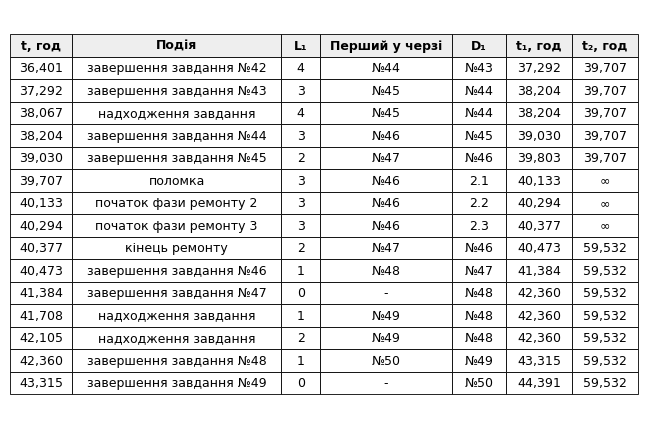

In [8]:
header, rows = save_protocol(1, False, [(36.0, 44.0)], "protocol_base.csv")

   67.587 | task #54 done      | L1 =  6 | head: 1#56   | D1: 1#55   | t1 =    68.345 | t2 =    69.045 | D3: free
   68.345 | task #55 done      | L1 =  5 | head: 1#57   | D1: 1#56   | t1 =    69.207 | t2 =    69.045 | D3: free
   68.495 | arrival of task    | L1 =  6 | head: 1#57   | D1: 1#56   | t1 =    69.207 | t2 =    69.045 | D3: free
   69.045 | breakdown          | L1 =  3 | head: 1#60   | D1: 2.1    | t1 =    71.366 | t2 =       inf | D3: free
   69.145 | arrival of task    | L1 =  4 | head: 1#60   | D1: 2.1    | t1 =    71.366 | t2 =       inf | D3: free
   70.776 | arrival of task    | L1 =  5 | head: 1#60   | D1: 2.1    | t1 =    71.366 | t2 =       inf | D3: free
   71.366 | repair phase 2     | L1 =  5 | head: 1#60   | D1: 2.2    | t1 =    72.722 | t2 =       inf | D3: free
  299.604 | repair phase 3     | L1 =  2 | head: 1#301  | D1: 2.3    | t1 =   301.239 | t2 =       inf | D3: free
  299.810 | arrival of task    | L1 =  3 | head: 1#301  | D1: 2.3    | t1 =   301.239 | 

<ipython-input-6-5cc75e32d5b9>:45: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(path, dpi=200, bbox_inches="tight", pad_inches=0.05)
<ipython-input-6-5cc75e32d5b9>:45: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(path, dpi=200, bbox_inches="tight", pad_inches=0.05)


   рисунок збережено: results/protocol_modified.png


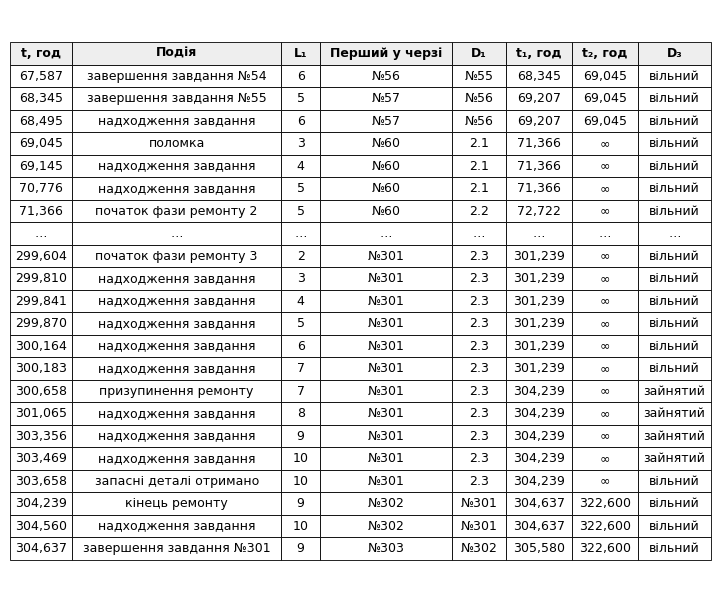

In [9]:
header, rows = save_protocol(2, True, [(67.5, 72.5), (299.5, 305.0)], "protocol_modified.csv")

In [10]:
verification_rows = check_input_reaction()

    1. початкові значення               U 0.849 (0.850)  P_рем 0.101 (0.101)  W 9.86  L 9.00  P_суб 0.000
    2. інтервал надходжень 1,5 год      U 0.568 (0.567)  P_рем 0.101 (0.101)  W 2.05  L 0.80  P_суб 0.000
    3. інтервал надходжень 2 год        U 0.425 (0.425)  P_рем 0.101 (0.101)  W 1.62  L 0.38  P_суб 0.000
    4. час обробки 0,3 год              U 0.651 (0.650)  P_рем 0.101 (0.101)  W 2.06  L 1.41  P_суб 0.000
    5. безвідмовна робота 15 год        U 0.850 (0.850)  P_рем 0.130 (0.130)  W 24.11  L 23.26  P_суб 0.000
    6. безвідмовна робота 40 год        U 0.849 (0.850)  P_рем 0.053 (0.053)  W 5.21  L 4.36  P_суб 0.000
    7. фаза ремонту 0,25 год            U 0.848 (0.850)  P_рем 0.036 (0.036)  W 4.21  L 3.36  P_суб 0.000
    8. фаза ремонту 1 год               U 0.849 (0.850)  P_рем 0.130 (0.130)  W 25.00  L 24.14  P_суб 0.000
    9. без поломок                      U 0.850 (0.850)  P_рем 0.000 (0.000)  W 3.31  L 2.46  P_суб 0.000
   10. модиф.: початкові значення       U 

<ipython-input-6-5cc75e32d5b9>:45: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(path, dpi=200, bbox_inches="tight", pad_inches=0.05)
<ipython-input-6-5cc75e32d5b9>:45: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(path, dpi=200, bbox_inches="tight", pad_inches=0.05)


   рисунок збережено: results/table_3_5_verification.png


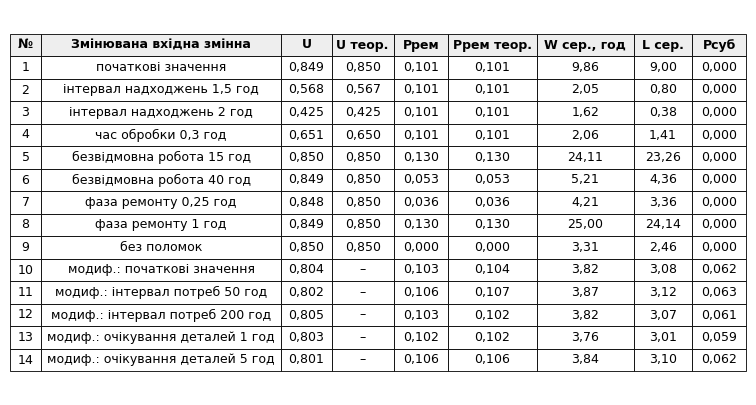

In [11]:
table_image(VERIFICATION_HEADER, verification_rows, "table_3_5_verification.png",
            [0.4, 3.1, 0.65, 0.8, 0.7, 1.15, 1.25, 0.75, 0.7], comma_cols=range(2, 9))

In [12]:
import csv
import math
import os
import statistics as st
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
from scipy import stats


T_MOD = 100_000
T_WARM = 1000
REL_EPS = 0.05
PILOT_RUNS = 20
OUT_DIR = os.environ.get("B19_OUT", "results")
SHOW_PLOTS = True
SHOW_PROGRESS = True
plt.rcParams["font.family"] = "DejaVu Sans"


@dataclass
class ModelVariant:
    name: str
    modified: bool
    changes: dict = field(default_factory=dict)

    def params(self):
        return {**PARAMS, **self.changes}


VARIANTS = [
    ModelVariant("базова", False),
    ModelVariant("лише субпідрядник", True, {"use_spare_parts": False}),
    ModelVariant("лише запасні деталі", True, {"use_subcontractor": False}),
    ModelVariant("модифікована", True),
]
BASE, MODIFIED = VARIANTS[0], VARIANTS[3]


def mean_and_sd(values):
    return st.mean(values), st.stdev(values)


def confidence_halfwidth(values, beta=0.95):
    n = len(values)
    return stats.t.ppf((1 + beta) / 2, n - 1) * st.stdev(values) / math.sqrt(n)


def required_runs(values, rel_eps=REL_EPS):
    m, s = mean_and_sd(values)
    return math.ceil(20 * (s / (rel_eps * m)) ** 2)


def observe_running_estimates(modified, seeds, t_max, step):
    curves = []
    for seed in seeds:
        model = MachineModel(seed=seed, warmup=0.0, modified=modified)
        times, util, wait = [], [], []
        for t in range(step, t_max + 1, step):
            model.run(t)
            times.append(t)
            util.append(model.busy_job / model.T)
            wait.append(model.sum_w / model.n_out if model.n_out else 0.0)
        curves.append({"t": times, "U": util, "W": wait})
    return curves


def spread_between_runs(curves, key, moment):
    i = curves[0]["t"].index(moment)
    values = [c[key][i] for c in curves]
    return max(values) - min(values)


def average_queue_over_runs(modified, n_runs, t_max, step, seed0=10_000):
    moments = list(range(step, t_max + 1, step))
    total = [0.0] * len(moments)
    for k in range(n_runs):
        model = MachineModel(seed=seed0 + k, modified=modified)
        for i, t in enumerate(moments):
            model.run(t)
            total[i] += len(model.queue1)
    return moments, [s / n_runs for s in total]


def run_series(variant, n_runs, seed0):
    reports = []
    for k in range(n_runs):
        model = MachineModel(seed0 + k, T_WARM, variant.modified, variant.params())
        reports.append(model.run(T_MOD).report())
        if SHOW_PROGRESS and ((k + 1) % 10 == 0 or k + 1 == n_runs):
            print(f"\r   {variant.name}: виконано {k + 1} з {n_runs} прогонів", end="", flush=True)
    if SHOW_PROGRESS:
        print()
    return reports


def save_table(filename, header, rows):
    os.makedirs(OUT_DIR, exist_ok=True)
    path = os.path.join(OUT_DIR, filename)
    with open(path, "w", newline="", encoding="utf-8-sig") as f:
        writer = csv.writer(f, delimiter=";")
        writer.writerow(header)
        writer.writerows(rows)
    print(f"   таблицю збережено: {path}")


def column(reports, key):
    return [r[key] for r in reports]


def one_factor_anova(groups, alpha=0.05):
    q, p = len(groups), len(groups[0])
    grand_mean = st.mean([x for g in groups for x in g])
    d_factor = p * sum((st.mean(g) - grand_mean) ** 2 for g in groups) / (q - 1)
    d_error = sum((x - st.mean(g)) ** 2 for g in groups for x in g) / (q * (p - 1))
    f_value = d_factor / d_error
    f_crit = stats.f.ppf(1 - alpha, q - 1, q * (p - 1))
    return {"D_F": d_factor, "D_E": d_error, "F": f_value, "F_crit": f_crit}


def chi2_normal_test(values, intervals=7, alpha=0.05):
    m, s = mean_and_sd(values)
    bounds = [stats.norm.ppf(i / intervals, m, s) for i in range(1, intervals)]
    observed = [0] * intervals
    for x in values:
        observed[sum(x > b for b in bounds)] += 1
    expected = len(values) / intervals
    chi2 = sum((o - expected) ** 2 / expected for o in observed)
    chi2_crit = stats.chi2.ppf(1 - alpha, intervals - 1 - 2)
    return {"chi2": chi2, "chi2_crit": chi2_crit, "observed": observed}


THINNING = 50
LAW_CANDIDATES = {
    "експоненційний зі зсувом": (stats.expon, {}),
    "гамма": (stats.gamma, {"floc": 0}),
    "Вейбулла": (stats.weibull_min, {"floc": 0}),
    "логнормальний": (stats.lognorm, {"floc": 0}),
}


def collect_task_times(variant, seed=1):
    model = MachineModel(seed, T_WARM, variant.modified, variant.params())
    model.keep_sojourns = True
    model.run(T_MOD)
    return model.sojourns


def chi2_fit(values, law, fixed, intervals=15, alpha=0.05):
    params = law.fit(values, **fixed)
    bounds = [law.ppf(i / intervals, *params) for i in range(1, intervals)]
    observed = [0] * intervals
    for x in values:
        observed[sum(x > b for b in bounds)] += 1
    expected = len(values) / intervals
    chi2 = sum((o - expected) ** 2 / expected for o in observed)
    n_params = len(params) - len(fixed)
    chi2_crit = stats.chi2.ppf(1 - alpha, intervals - 1 - n_params)
    return params, chi2, chi2_crit


def identify_task_time_law(variant):
    times = collect_task_times(variant)
    sample = times[::THINNING]
    print(f"   {variant.name}: завдань {len(times)}, вибірка {len(sample)}, середнє {st.mean(times):.3f}, "
          f"СКВ {st.stdev(times):.3f}, мінімум {min(times):.3f}, максимум {max(times):.2f}")
    rows, best = [], None
    for name, (law, fixed) in LAW_CANDIDATES.items():
        params, chi2, crit = chi2_fit(sample, law, fixed)
        verdict = "приймається" if chi2 < crit else "відхиляється"
        rows.append([variant.name, name, " ".join(f"{p:.3f}" for p in params), f"{chi2:.1f}", f"{crit:.1f}", verdict])
        print(f"      {name:26s} χ² {chi2:7.1f}, χ²крит {crit:.1f} – {verdict}")
        if best is None or chi2 < best[2]:
            best = (name, law, chi2, params)
    return times, best, rows


TRIAL_RUNS = 30
TRIAL_SEED = 30_000
FASTER_SETUP = {"setup": (0.25, 0.10)}
FASTER_REPAIR = {"phase_mean": 0.5}

BASE_IMPROVEMENTS = [
    ModelVariant("базовий (поточний стан)", False),
    ModelVariant("1. швидша наладка", False, FASTER_SETUP),
    ModelVariant("2. швидший ремонт", False, FASTER_REPAIR),
    ModelVariant("3. надійніший верстат", False, {"uptime": (30.0, 3.0)}),
    ModelVariant("1 + 2 разом", False, {**FASTER_SETUP, **FASTER_REPAIR}),
]
MODIFIED_IMPROVEMENTS = [
    ModelVariant("модифікований (поточний стан)", True),
    ModelVariant("4. склад запасних деталей", True, {"use_spare_parts": False}),
    ModelVariant("5. поріг передачі 5 завдань", True, {"keep": 5}),
    ModelVariant("модифікований + 1", True, FASTER_SETUP),
]


def average_characteristics(variant):
    reports = run_series(variant, TRIAL_RUNS, TRIAL_SEED)
    return {key: st.mean(column(reports, key)) for key in ("U", "P_rep", "W", "L", "P_sub")}


def percent_change(value, reference):
    return 100 * (value - reference) / reference


def compare_improvements(group, title, filename):
    print(f"   {title}")
    reference, rows = None, []
    for variant in group:
        values = average_characteristics(variant)
        if reference is None:
            reference, change = values, "–"
        else:
            change = f"{percent_change(values['W'], reference['W']):+.0f} %"
        rows.append([variant.name] + [f"{values[k]:.4f}" for k in ("U", "P_rep", "W", "L", "P_sub")] + [change])
        print(f"   {variant.name:32s} U {values['U']:.3f}  P_рем {values['P_rep']:.3f}  "
              f"W {values['W']:.2f}  L {values['L']:.2f}  P_суб {values['P_sub']:.3f}  ΔW {change}")
    save_table(filename, ["варіант", "U", "P_рем", "W", "L", "P_суб", "зміна W"], rows)


def save_and_show(fig, filename):
    os.makedirs(OUT_DIR, exist_ok=True)
    path = os.path.join(OUT_DIR, filename)
    fig.savefig(path, dpi=170)
    print(f"   графік збережено: {path}")
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)


def plot_running_estimates(curves, filename):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for i, c in enumerate(curves):
        ax[0].plot(c["t"], c["U"], lw=1, label=f"прогін {i + 1}")
        ax[1].plot(c["t"], c["W"], lw=1, label=f"прогін {i + 1}")
    ax[0].set_ylabel("Завантаження верстата U")
    ax[1].set_ylabel("Середній час виконання W, год")
    for a in ax:
        a.set_xlabel("Модельний час, год"); a.grid(alpha=.3); a.legend(fontsize=8)
    fig.tight_layout()
    save_and_show(fig, filename)


def plot_warmup(series, filename):
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    for label, (moments, queue) in series.items():
        ax.plot(moments, queue, lw=1.2, label=label)
    ax.set_xlabel("Модельний час, год"); ax.set_ylabel("Середня довжина черги L₁(t)")
    ax.grid(alpha=.3); ax.legend()
    fig.tight_layout()
    save_and_show(fig, filename)


def plot_wait_histograms(results, filename):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for a, variant in zip(ax, (BASE, MODIFIED)):
        values = column(results[variant.name], "W")
        m, s = mean_and_sd(values)
        a.hist(values, bins=10, density=True, alpha=.7, edgecolor="k")
        xs = [min(values) + (max(values) - min(values)) * i / 200 for i in range(201)]
        a.plot(xs, [stats.norm.pdf(x, m, s) for x in xs], "r", lw=1.5, label="нормальний закон")
        a.set_title(f"{variant.name} модель"); a.set_xlabel("Середній час виконання W за прогін, год")
        a.set_ylabel("Щільність"); a.legend(fontsize=8); a.grid(alpha=.3)
    fig.tight_layout()
    save_and_show(fig, filename)


def plot_task_time_histograms(fits, filename):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for a, (variant, (times, best, _)) in zip(ax, fits.items()):
        name, law, _, params = best
        a.hist(times, bins=60, density=True, alpha=.7, edgecolor="k", lw=0.3)
        top = sorted(times)[int(0.995 * len(times))]
        xs = [top * i / 300 for i in range(1, 301)]
        a.plot(xs, [law.pdf(x, *params) for x in xs], "r", lw=1.5, label=f"закон: {name}")
        a.set_xlim(0, top)
        a.set_title(f"{variant} модель"); a.set_xlabel("Час виконання завдання W, год")
        a.set_ylabel("Щільність"); a.legend(fontsize=8); a.grid(alpha=.3)
    fig.tight_layout()
    save_and_show(fig, filename)


def plot_variant_comparison(results, filename):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    names = [v.name for v in VARIANTS]
    for a, key, label in ((ax[0], "U", "Завантаження верстата U"),
                          (ax[1], "W", "Середній час виконання W, год")):
        a.boxplot([column(results[n], key) for n in names])
        a.set_xticks(range(1, len(names) + 1), [n.replace(" ", "\n") for n in names], fontsize=8)
        a.set_ylabel(label); a.grid(alpha=.3)
    fig.tight_layout()
    save_and_show(fig, filename)

In [13]:
os.makedirs(OUT_DIR, exist_ok=True)
moments_to_report = (10_000, 20_000, 50_000, 100_000, 150_000, 200_000)

1. Тривалість моделювання: розкид поточних середніх між 5 прогонами


<ipython-input-12-aedd1312bf17>:225: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(path, dpi=170)
<ipython-input-12-aedd1312bf17>:225: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(path, dpi=170)


   графік збережено: results/running_base.png


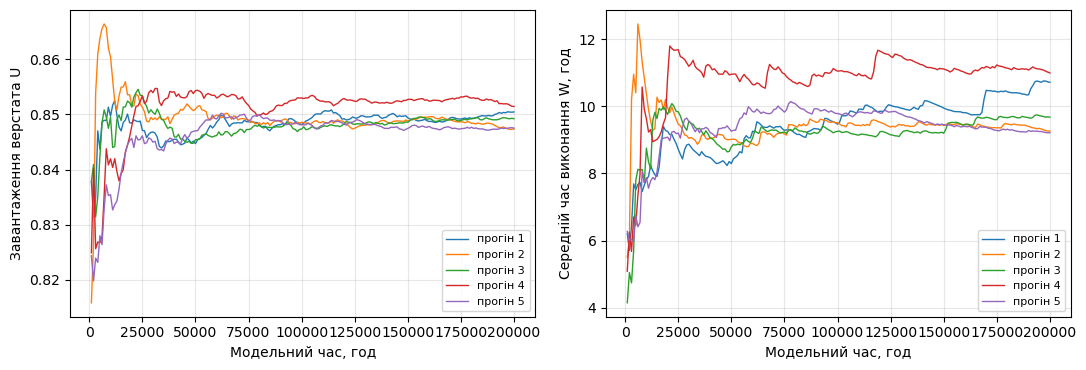

   базова        t =  10000: U 0.0250, W 2.581
   базова        t =  20000: U 0.0060, W 1.801
   базова        t =  50000: U 0.0096, W 2.661
   базова        t = 100000: U 0.0057, W 1.794
   базова        t = 150000: U 0.0052, W 1.913
   базова        t = 200000: U 0.0041, W 1.779
   графік збережено: results/running_mod.png


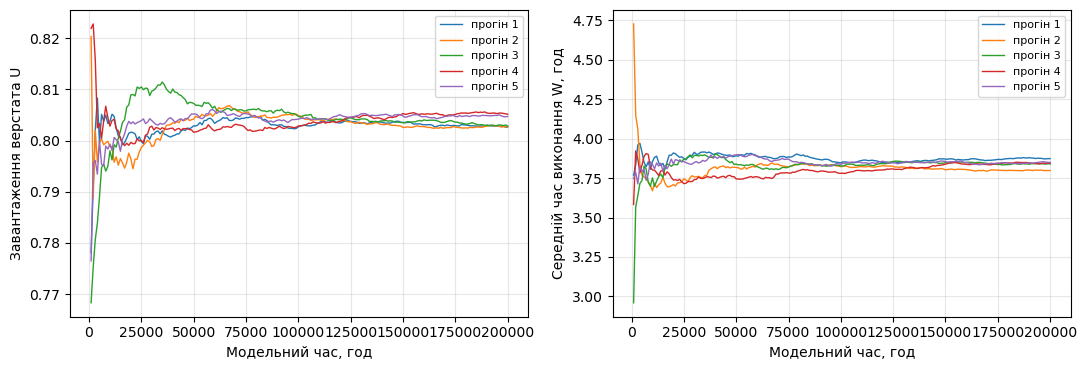

   модифікована  t =  10000: U 0.0057, W 0.185
   модифікована  t =  20000: U 0.0125, W 0.201
   модифікована  t =  50000: U 0.0056, W 0.153
   модифікована  t = 100000: U 0.0022, W 0.066
   модифікована  t = 150000: U 0.0027, W 0.068
   модифікована  t = 200000: U 0.0025, W 0.075
   таблицю збережено: results/table_4_1_spread.csv


In [14]:
print("1. Тривалість моделювання: розкид поточних середніх між 5 прогонами")
rows = []
for variant, filename in ((BASE, "running_base.png"), (MODIFIED, "running_mod.png")):
    curves = observe_running_estimates(variant.modified, range(1, 6), 200_000, 1000)
    plot_running_estimates(curves, filename)
    for moment in moments_to_report:
        du, dw = spread_between_runs(curves, "U", moment), spread_between_runs(curves, "W", moment)
        rows.append([variant.name, moment, f"{du:.4f}", f"{dw:.3f}"])
        print(f"   {variant.name:13s} t = {moment:6d}: U {du:.4f}, W {dw:.3f}")
save_table("table_4_1_spread.csv", ["модель", "час, год", "розкид U", "розкид W"], rows)

2. Перехідний період: середня довжина черги L1(t)


<ipython-input-12-aedd1312bf17>:225: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(path, dpi=170)
<ipython-input-12-aedd1312bf17>:225: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(path, dpi=170)


   графік збережено: results/warmup.png


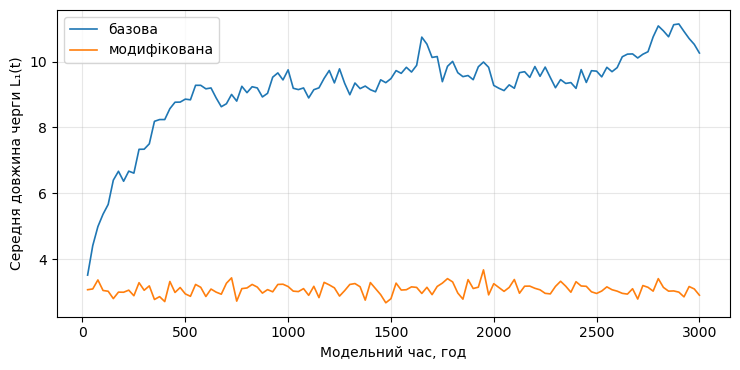

   таблицю збережено: results/warmup_queue.csv


In [15]:
print("2. Перехідний період: середня довжина черги L1(t)")
warmup_series = {v.name: average_queue_over_runs(v.modified, 300, 3000, 25) for v in (BASE, MODIFIED)}
plot_warmup(warmup_series, "warmup.png")
moments = warmup_series[BASE.name][0]
save_table("warmup_queue.csv", ["час, год"] + list(warmup_series),
           [[t] + [f"{q[i]:.3f}" for _, q in warmup_series.values()] for i, t in enumerate(moments)])

In [16]:
print("3. Кількість прогонів (пробна серія)")
n_runs, rows = PILOT_RUNS, []
for variant, seed0 in ((BASE, 500), (MODIFIED, 700)):
    pilot = run_series(variant, PILOT_RUNS, seed0)
    for key in ("U", "W"):
        values = column(pilot, key)
        m, s = mean_and_sd(values)
        p = required_runs(values)
        n_runs = max(n_runs, p)
        rows.append([variant.name, key, f"{m:.4f}", f"{s:.4f}", f"{REL_EPS * m:.4f}", p])
        print(f"   {variant.name:13s} {key}: середнє {m:.4f}, σ {s:.4f}, ε {REL_EPS * m:.4f}, p = {p}")
save_table("table_4_2_pilot.csv", ["модель", "характеристика", "середнє", "σ", "ε", "p"], rows)

3. Кількість прогонів (пробна серія)
   базова: виконано 20 з 20 прогонів
   базова        U: середнє 0.8495, σ 0.0020, ε 0.0425, p = 1
   базова        W: середнє 10.4730, σ 0.5790, ε 0.5236, p = 25
   модифікована: виконано 20 з 20 прогонів
   модифікована  U: середнє 0.8032, σ 0.0017, ε 0.0402, p = 1
   модифікована  W: середнє 3.8195, σ 0.0349, ε 0.1910, p = 1
   таблицю збережено: results/table_4_2_pilot.csv


In [17]:
print("4. Основна серія")
def main_series(n):
    return {v.name: run_series(v, n, 20_000 + 1000 * i) for i, v in enumerate(VARIANTS)}
results = main_series(n_runs)
needed = max(required_runs(column(results[v.name], k)) for v in (BASE, MODIFIED) for k in ("U", "W"))
print(f"   перевірка: прийнято p = {n_runs}, за σ основної серії потрібно p = {needed}")
if needed > n_runs:
    n_runs = math.ceil(needed / 10) * 10
    results = main_series(n_runs)
    print(f"   основну серію повторено з p = {n_runs}")
keys = ("U", "P_rep", "W", "sigma_W", "W_min", "W_max", "L", "lambda_out", "P_sub")
rows = []
for v in VARIANTS:
    reports = results[v.name]
    cells = [f"{st.mean(column(reports, k)):.4f} ± {confidence_halfwidth(column(reports, k)):.4f}" for k in keys]
    rows.append([v.name] + cells)
    print(f"   {v.name:20s} " + ", ".join(f"{k} {c}" for k, c in zip(keys, cells)))
save_table("table_4_3_4_5_estimates.csv", ["варіант"] + list(keys), rows)
rows = []
for v in (BASE, MODIFIED):
    reports = results[v.name]
    for key in ("U", "W", "W_min", "W_max"):
        values = column(reports, key)
        rows.append([v.name, key, f"{min(values):.4f}", f"{max(values):.4f}"])
        print(f"   {v.name:13s} {key:6s}: найменше {min(values):.4f}, найбільше {max(values):.4f} за {len(values)} прогонів")
save_table("table_4_3_min_max.csv", ["модель", "характеристика", "мінімум", "максимум"], rows)

4. Основна серія
   базова: виконано 25 з 25 прогонів
   лише субпідрядник: виконано 25 з 25 прогонів
   лише запасні деталі: виконано 25 з 25 прогонів
   модифікована: виконано 25 з 25 прогонів
   перевірка: прийнято p = 25, за σ основної серії потрібно p = 51
   базова: виконано 60 з 60 прогонів
   лише субпідрядник: виконано 60 з 60 прогонів
   лише запасні деталі: виконано 60 з 60 прогонів
   модифікована: виконано 60 з 60 прогонів
   основну серію повторено з p = 60
   базова               U 0.8497 ± 0.0007, P_rep 0.1012 ± 0.0002, W 10.2387 ± 0.2115, sigma_W 9.4185 ± 0.3377, W_min 0.3964 ± 0.0089, W_max 66.0397 ± 3.0659, L 9.3893 ± 0.2165, lambda_out 0.9997 ± 0.0008, P_sub 0.0000 ± 0.0000
   лише субпідрядник    U 0.8050 ± 0.0004, P_rep 0.1011 ± 0.0002, W 3.7602 ± 0.0072, sigma_W 2.2867 ± 0.0047, W_min 0.3856 ± 0.0080, W_max 16.4964 ± 0.3238, L 3.0138 ± 0.0093, lambda_out 0.9402 ± 0.0005, P_sub 0.0603 ± 0.0005
   лише запасні деталі  U 0.8499 ± 0.0007, P_rep 0.1037 ± 0.0002, W 10.

In [18]:
print("5. Дисперсійний аналіз (фактор – варіант моделі)")
rows = []
for key in ("U", "W"):
    a = one_factor_anova([column(results[v.name], key) for v in VARIANTS])
    rows.append(["усі 4 варіанти", key, f"{a['D_F']:.6f}", f"{a['D_E']:.7f}", f"{a['F']:.2f}", f"{a['F_crit']:.2f}"])
    print(f"   {key}: D_F {a['D_F']:.5f}, D_E {a['D_E']:.7f}, F {a['F']:.1f}, F_крит {a['F_crit']:.2f}")
for first, second in ((BASE, MODIFIED), (BASE, VARIANTS[2]), (VARIANTS[1], MODIFIED)):
    for key in ("U", "W", "P_rep"):
        a = one_factor_anova([column(results[first.name], key), column(results[second.name], key)])
        rows.append([f"{first.name} / {second.name}", key, f"{a['D_F']:.6f}", f"{a['D_E']:.7f}",
                     f"{a['F']:.2f}", f"{a['F_crit']:.2f}"])
        print(f"   {first.name} / {second.name}, {key}: F {a['F']:.2f}, F_крит {a['F_crit']:.2f}")
save_table("table_4_6_anova.csv", ["порівняння", "характеристика", "D_F", "D_E", "F", "F_крит"], rows)

5. Дисперсійний аналіз (фактор – варіант моделі)
   U: D_F 0.04120, D_E 0.0000050, F 8207.1, F_крит 2.64
   W: D_F 921.94921, D_E 0.3092382, F 2981.4, F_крит 2.64
   базова / модифікована, U: F 12139.89, F_крит 3.92
   базова / модифікована, W: F 3674.38, F_крит 3.92
   базова / модифікована, P_rep: F 303.72, F_крит 3.92
   базова / лише запасні деталі, U: F 0.09, F_крит 3.92
   базова / лише запасні деталі, W: F 20.94, F_крит 3.92
   базова / лише запасні деталі, P_rep: F 259.77, F_крит 3.92
   лише субпідрядник / модифікована, U: F 12.42, F_крит 3.92
   лише субпідрядник / модифікована, W: F 160.75, F_крит 3.92
   лише субпідрядник / модифікована, P_rep: F 325.16, F_крит 3.92
   таблицю збережено: results/table_4_6_anova.csv


6. Закон розподілу оцінок (критерій χ²)
   базова        U: χ² 1.37, χ²крит 9.49 – приймається
   базова        W: χ² 17.23, χ²крит 9.49 – відхиляється
   модифікована  U: χ² 4.40, χ²крит 9.49 – приймається
   модифікована  W: χ² 4.63, χ²крит 9.49 – приймається
   таблицю збережено: results/table_4_4_chi2.csv


<ipython-input-12-aedd1312bf17>:225: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(path, dpi=170)
<ipython-input-12-aedd1312bf17>:225: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(path, dpi=170)


   графік збережено: results/hist_W.png


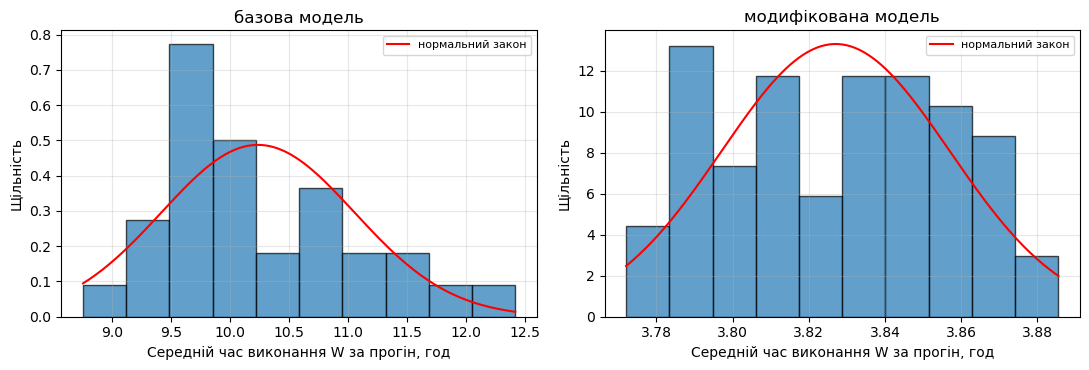

<ipython-input-12-aedd1312bf17>:225: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(path, dpi=170)
<ipython-input-12-aedd1312bf17>:225: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(path, dpi=170)


   графік збережено: results/variants.png


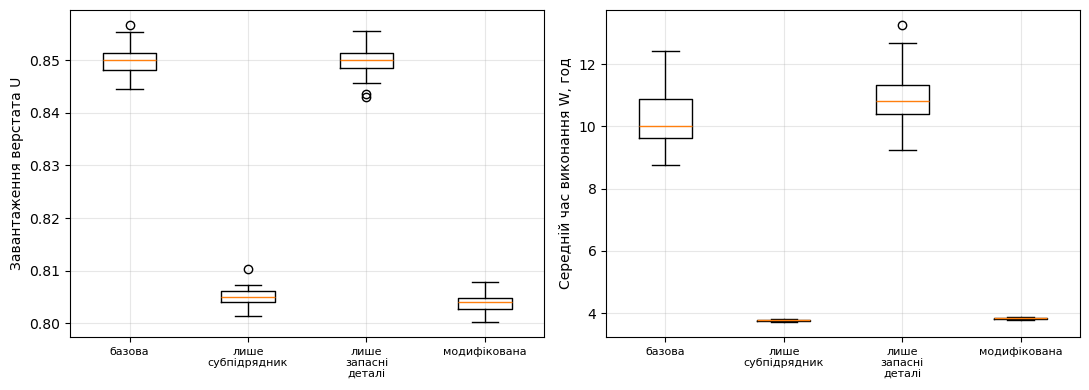

In [19]:
print("6. Закон розподілу оцінок (критерій χ²)")
rows = []
for v in (BASE, MODIFIED):
    for key in ("U", "W"):
        c = chi2_normal_test(column(results[v.name], key))
        verdict = "приймається" if c["chi2"] < c["chi2_crit"] else "відхиляється"
        rows.append([v.name, key, f"{c['chi2']:.2f}", f"{c['chi2_crit']:.2f}", verdict])
        print(f"   {v.name:13s} {key}: χ² {c['chi2']:.2f}, χ²крит {c['chi2_crit']:.2f} – {verdict}")
save_table("table_4_4_chi2.csv", ["модель", "оцінка", "χ²", "χ²крит", "гіпотеза"], rows)
plot_wait_histograms(results, "hist_W.png")
plot_variant_comparison(results, "variants.png")

6а. Закон розподілу часу виконання окремого завдання
   базова: завдань 98788, вибірка 1976, середнє 9.500, СКВ 8.364, мінімум 0.430, максимум 57.44
      експоненційний зі зсувом   χ²    15.2, χ²крит 21.0 – приймається
      гамма                      χ²    22.6, χ²крит 21.0 – відхиляється
      Вейбулла                   χ²    28.9, χ²крит 21.0 – відхиляється
      логнормальний              χ²   100.9, χ²крит 21.0 – відхиляється
   модифікована: завдань 92802, вибірка 1857, середнє 3.848, СКВ 2.350, мінімум 0.393, максимум 19.13
      експоненційний зі зсувом   χ²   269.8, χ²крит 21.0 – відхиляється
      гамма                      χ²    80.5, χ²крит 21.0 – відхиляється
      Вейбулла                   χ²    49.4, χ²крит 21.0 – відхиляється
      логнормальний              χ²   228.0, χ²крит 21.0 – відхиляється
   таблицю збережено: results/table_4_4a_task_time_law.csv


<ipython-input-12-aedd1312bf17>:225: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.savefig(path, dpi=170)
<ipython-input-12-aedd1312bf17>:225: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.savefig(path, dpi=170)


   графік збережено: results/hist_task_time.png


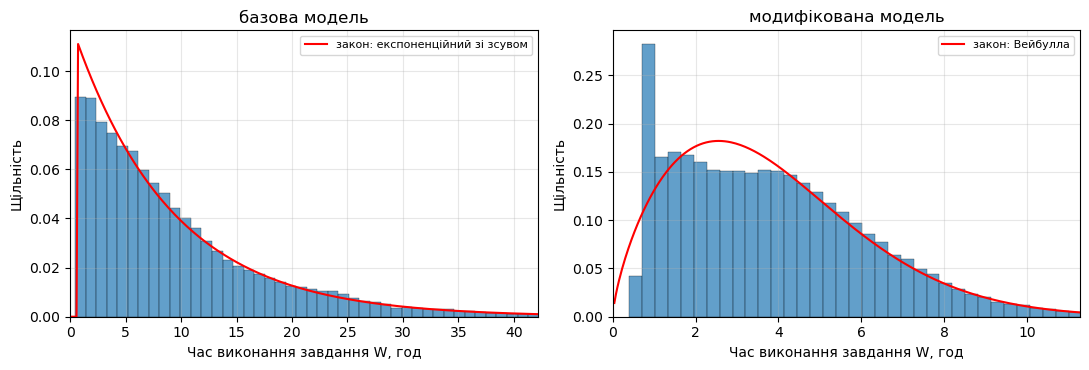

In [20]:
print("6а. Закон розподілу часу виконання окремого завдання")
fits, rows = {}, []
for v in (BASE, MODIFIED):
    times, best, law_rows = identify_task_time_law(v)
    fits[v.name] = (times, best, law_rows)
    rows += law_rows
save_table("table_4_4a_task_time_law.csv", ["модель", "закон", "параметри", "χ²", "χ²крит", "гіпотеза"], rows)
plot_task_time_histograms(fits, "hist_task_time.png")

In [21]:
print("7. Пробний запуск пропозицій щодо поліпшення системи")
compare_improvements(BASE_IMPROVEMENTS, "пропозиції для базової системи", "table_5_1_base.csv")
compare_improvements(MODIFIED_IMPROVEMENTS, "пропозиції для модифікованої системи", "table_5_1_modified.csv")

7. Пробний запуск пропозицій щодо поліпшення системи
   пропозиції для базової системи
   базовий (поточний стан): виконано 30 з 30 прогонів
   базовий (поточний стан)          U 0.850  P_рем 0.101  W 10.18  L 9.34  P_суб 0.000  ΔW –
   1. швидша наладка: виконано 30 з 30 прогонів
   1. швидша наладка                U 0.750  P_рем 0.101  W 3.45  L 2.70  P_суб 0.000  ΔW -66 %
   2. швидший ремонт: виконано 30 з 30 прогонів
   2. швидший ремонт                U 0.850  P_рем 0.070  W 6.11  L 5.26  P_суб 0.000  ΔW -40 %
   3. надійніший верстат: виконано 30 з 30 прогонів
   3. надійніший верстат            U 0.851  P_рем 0.070  W 6.46  L 5.62  P_суб 0.000  ΔW -37 %
   1 + 2 разом: виконано 30 з 30 прогонів
   1 + 2 разом                      U 0.750  P_рем 0.070  W 2.72  L 1.97  P_суб 0.000  ΔW -73 %
   таблицю збережено: results/table_5_1_base.csv
   пропозиції для модифікованої системи
   модифікований (поточний стан): виконано 30 з 30 прогонів
   модифікований (поточний стан)    U 0.804